# Claim Adjudication — End-to-End

Invoice → Extraction → Policy retrieval → Agent 1 → Calculation → Agent 2 → Final report

- **SFT + QLoRA:** Fine-tunes the vision model to extract invoice data.
- **DPO + QLoRA:** Fine-tunes the reasoning model for policy selection and review.
- **RAG:** Retrieves policy evidence for each invoice item.
- **Deterministic calculation:** Python applies limits and co-pay; unresolved items remain pending.

## 1. Setup

In [5]:
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
from uuid import uuid4
import copy
import hashlib
import html
import io
import json
import os
import shutil
import sys
import tempfile
import time

import httpx
import pandas as pd
from IPython.display import HTML, Image, display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((root for candidate in candidates
             for root in [candidate, candidate / 'optum_claim_adjudication']
             if (root / 'src/components/agentic_workflow/graph.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the claim adjudication project.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


def show_html(markup, text=''):
    display(HTML(
        '<div style="background:#ffffff;color:#172b4d;color-scheme:light;'
        'font-family:Arial,sans-serif;font-size:15px;line-height:1.5;'
        'padding:12px;overflow-x:auto;border-radius:6px">' + markup + '</div>'
    ))


def show(frame):
    markup = frame.to_html(index=False, escape=True, na_rep='—')
    markup = markup.replace('<table border="1" class="dataframe">',
        '<table style="border-collapse:collapse;width:100%;font-size:15px;'
        'color:#172b4d;background:#ffffff">')
    markup = markup.replace('<th>', '<th style="background:#16324f;color:#ffffff;'
        'text-align:left;padding:12px;border:1px solid #cbd5e1">')
    markup = markup.replace('<td>', '<td style="background:#ffffff;color:#172b4d;'
        'text-align:left;padding:12px;border:1px solid #cbd5e1;vertical-align:top">')
    show_html(markup)


def show_image(path):
    display(Image(filename=str(path)))


def check_services(root):
    """Check the application environment and the selected served adapters."""
    expected_environment = root.parent / '.venv'
    if Path(sys.prefix).resolve() != expected_environment.resolve():
        raise RuntimeError(f'Select the kernel at {expected_environment}/bin/python.')
    os.environ['OPTUM_REASONING_BACKEND'] = 'text_dpo'
    os.environ['VLM_BASE_URL'] = 'http://127.0.0.1:8000/v1'
    os.environ.setdefault('HF_HUB_OFFLINE', '1')
    os.environ.setdefault('TRANSFORMERS_OFFLINE', '1')
    rows = []
    for role, folder, port, served in [
        ('Invoice extraction', 'qwen25_finetune_sf_qlora', 8000, 'invoice-extractor'),
        ('Policy selection and review', 'qwen_25_finetune_dpo_qlora', 8002, 'reasoning-dpo'),
    ]:
        model_root = root / 'models' / folder
        pointer = json.loads((model_root / 'latest_successful.json').read_text())
        adapter = (model_root / pointer['adapter_path']).resolve()
        if not (adapter / 'adapter_model.safetensors').is_file():
            raise FileNotFoundError(f'Selected adapter weights are missing: {adapter}')
        try:
            httpx.get(f'http://127.0.0.1:{port}/health', timeout=10).raise_for_status()
            response = httpx.get(f'http://127.0.0.1:{port}/v1/models', timeout=10)
            response.raise_for_status()
            cards = response.json()['data']
            card = next((card for card in cards if card['id'] == served), None)
            if card is None or Path(card['root']).resolve() != adapter:
                raise RuntimeError(f'{served} is not serving the selected adapter.')
            if port == 8000 and not any(card['id'] == 'qwen-base' for card in cards):
                raise RuntimeError('qwen-base is required for invoice-date extraction.')
        except httpx.HTTPError as exc:
            raise RuntimeError(f'{served} is unavailable on port {port}. Start its existing vLLM service.') from exc
        rows.append({'Component': role, 'Model': pointer['model_id'], 'Status': 'Ready'})
    return rows


def _index_hashes(directory):
    return {
        str(path.relative_to(directory)): hashlib.sha256(path.read_bytes()).hexdigest()
        for path in directory.rglob('*') if path.is_file() and path.name != 'LOCK'
    }


def run_workflow(root, image_path, invoice_date):
    """Execute one production request and retain its actual stage outputs."""
    from src.components.agentic_workflow.contracts import WorkflowReport
    from src.components.agentic_workflow.graph import create_claim_graph
    from src.components.agentic_workflow.workflow import initialize_claim_state
    from src.components.rag.retriever import PolicyRetriever
    from src.config.settings import get_settings

    request_id = uuid4().hex
    executed_at = datetime.now(timezone.utc).isoformat()
    settings = get_settings()
    snapshots = {}
    # A verified copy avoids the lock held by another Milvus Lite process.
    with tempfile.TemporaryDirectory(prefix='optum_notebook_policy_') as workspace:
        original_db = settings.rag.db_path
        isolated_db = Path(workspace) / 'policy.db'
        original_hashes = _index_hashes(original_db)
        shutil.copytree(original_db, isolated_db, ignore=shutil.ignore_patterns('LOCK'))
        if not original_hashes or original_hashes != _index_hashes(isolated_db) or original_hashes != _index_hashes(original_db):
            raise RuntimeError('Policy index changed while copying; retry the request.')
        retriever = PolicyRetriever(db_path=isolated_db, manifest_path=settings.rag.manifest_path)
        try:
            graph = create_claim_graph(
                endpoint='http://127.0.0.1:8000/v1', timeout=120,
                max_tokens=768, retriever=retriever,
            )
            initial = initialize_claim_state(
                image=image_path, invoice_date=invoice_date['invoice_date'],
                request_id=request_id, max_retries=1, request_timeout=360,
            )
            observed = copy.deepcopy(initial)
            started = time.perf_counter()
            for event in graph.stream(initial, config={'recursion_limit': 24}, stream_mode='updates'):
                for node, update in event.items():
                    observed.update(copy.deepcopy(update))
                    snapshots[node] = copy.deepcopy(observed)
            duration = time.perf_counter() - started
        finally:
            retriever.client.close()

    report = WorkflowReport.model_validate(observed['result']).model_dump(mode='json')
    if report['request_id'] != request_id:
        raise RuntimeError('The workflow returned a different request ID.')
    output_dir = root / 'notebooks/demo_artifact/results' / request_id
    output_dir.mkdir(parents=True, exist_ok=False)
    (output_dir / 'final_report.json').write_text(
        json.dumps({'invoice_date': invoice_date, 'workflow': report}, indent=2) + '\n'
    )
    (output_dir / 'validated_invoice.csv').write_text(report['extracted_csv'] or '')
    required = {
        'orchestrator', 'invoice_extraction', 'csv_validation', 'policy_retrieval',
        'policy_adjudication_agent', 'deterministic_adjudication',
        'reasoning_review_agent', 'final_response',
    }
    if (report['errors'] or report['status'] == 'FAILED' or not report['reviewed']
            or not required.issubset(snapshots) or report['claim'] is None):
        raise RuntimeError(f'Workflow incomplete. See {output_dir / "final_report.json"}: {report["errors"]}')
    if not all(row['request_id'] == request_id for row in report['trace']):
        raise RuntimeError('Execution trace contains another request ID.')
    return SimpleNamespace(
        report=report, stages=snapshots, request_id=request_id,
        output_dir=output_dir, executed_at=executed_at, duration=duration,
    )


def financial_summary(claim):
    """Keep pending amounts separate and preserve an unfinalized reimbursement."""
    labels = [
        ('Billed', 'billed_total'), ('Eligible', 'eligible_total'),
        ('Disallowed', 'disallowed_total'), ('Pending review', 'pending_review_total'),
        ('Co-pay (%)', 'copay_rate_percent'), ('Co-pay amount', 'copay_amount'),
        ('Final reimbursement', 'final_reimbursement'),
    ]
    return [
        {'Metric': label, 'Value': 'Not finalized' if claim[key] is None else claim[key],
         'Unit': '%' if key == 'copay_rate_percent' else claim['currency']}
        for label, key in labels
    ]

show(pd.DataFrame(check_services(ROOT)))

Component,Model,Status
Invoice extraction,Qwen/Qwen2.5-VL-3B-Instruct,Ready
Policy selection and review,Qwen/Qwen2.5-3B-Instruct,Ready


## 2. Input invoice

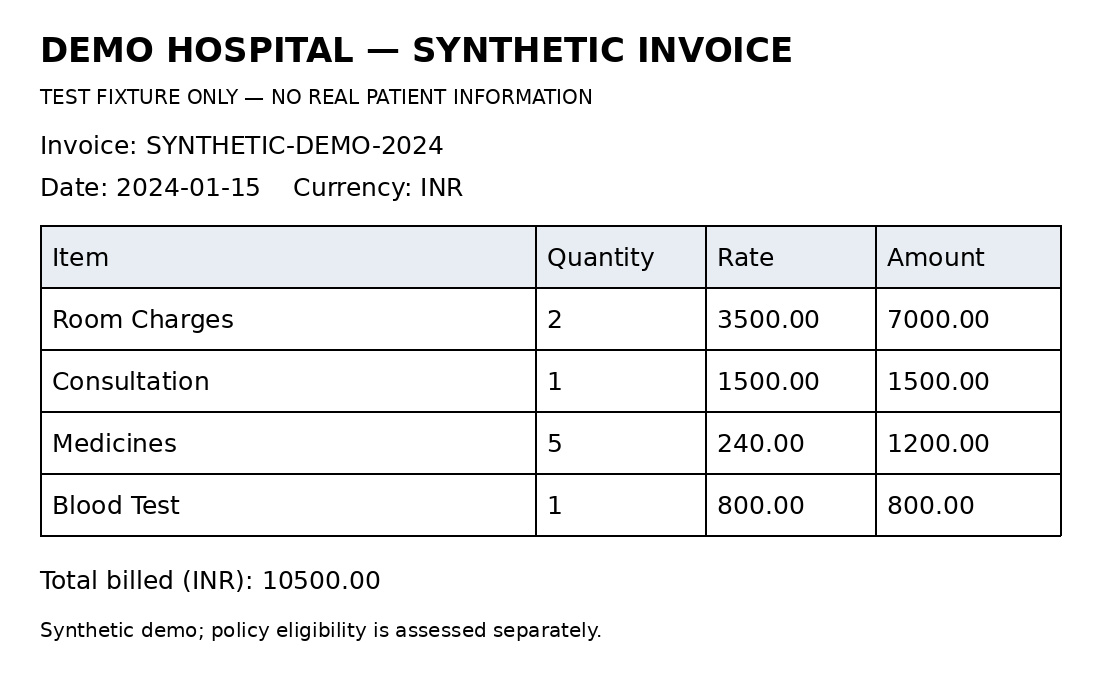

Invoice,Invoice date,Date status,Verification
invoice_2024.jpg,2024-01-15,FOUND,model_extracted_unverified


In [6]:
from UI.invoice_date import extract_invoice_date

IMAGE_PATH = ROOT / 'notebooks/demo_artifact/invoice_2024.jpg'
show_image(IMAGE_PATH)
date_metadata = extract_invoice_date(IMAGE_PATH, endpoint='http://127.0.0.1:8000/v1')
show(pd.DataFrame([{
    'Invoice': IMAGE_PATH.name,
    'Invoice date': date_metadata['invoice_date'],
    'Date status': date_metadata['status'],
    'Verification': date_metadata['verification_status'],
}]))
if date_metadata['status'] != 'FOUND':
    raise RuntimeError('Invoice date needs review before the workflow can run.')

## 3. Run workflow · Extract and validate

In [3]:
demo = run_workflow(ROOT, IMAGE_PATH, date_metadata)
final_report = demo.report
request_id = demo.request_id

validated = demo.stages['csv_validation']
if not validated.get('csv_validated'):
    raise RuntimeError('Invoice CSV validation failed.')
invoice = validated['invoice']
show(pd.read_csv(io.StringIO(validated['extracted_csv']), dtype=str, keep_default_na=False))
show(pd.DataFrame([{
    'Extraction model': final_report['metadata']['extraction']['returned_model'],
    'CSV validation': 'Passed',
    'Invoice items': len(invoice.lines),
}]))

/home/rishabh_mishra0440/optum_claim_adjudication/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Item,Quantity,Rate,Amount
Room Charges,2,3500.00,7000.00
Consultation,1,1500.00,1500.00
Medicines,5,240.00,1200.00
Blood Test,1,800.00,800.00


Extraction model,CSV validation,Invoice items
invoice-extractor,Passed,4


## 4. Retrieved policy evidence

In [4]:
rag = demo.stages['policy_retrieval']
evidence = [
    {'Item': invoice.lines[int(index)].item,
     'Policy': rule['rule_id'],
     'Category': rule['category'],
     'Conditions / evidence': rule['conditions']}
    for index, rules in rag['candidate_rules'].items()
    for rule in rules
]
show(pd.DataFrame(evidence))
show(pd.DataFrame([{'Retrieval status': rag['rag_status'], 'Evidence source': 'Milvus policy index'}]))

Item,Policy,Category,Conditions / evidence
Room Charges,COV-001,Room Charges,"Maximum reimbursement is INR 3,000 per billed day."
Room Charges,EXC-007,Television Charges,"Television, entertainment and room entertainment charges are excluded."
Room Charges,COV-002,ICU Charges,"Maximum reimbursement is INR 6,000 per billed ICU day."
Consultation,COV-003,Consultation,"Maximum reimbursement is INR 1,500 per consultation visit."
Consultation,EXC-017,Beauty Services,"Beauty, grooming and salon services are excluded."
Consultation,COV-004,Specialist Consultation,"Maximum reimbursement is INR 2,000 per specialist consultation visit."
Medicines,COV-005,Medicines,Covered at billed amount when medically related and not excluded.
Medicines,EXC-004,Health Supplements,"Health supplements, nutritional supplements and similar non-treatment products are excluded."
Medicines,COV-024,Hospital Nursing Supplies,Covered at billed amount when directly related to inpatient treatment.
Blood Test,COV-010,Blood Tests,Blood tests are covered at billed amount.


Retrieval status,Evidence source
milvus_live,Milvus policy index


## 5. Agent 1 · Policy selection

In [5]:
a1 = demo.stages['policy_adjudication_agent']
selections = {row['item_index']: row['suggested_status']
              for row in a1['metadata']['agent_1']['model_selections']}
show(pd.DataFrame([
    {'Item': invoice.lines[row.item_index].item,
     'Policy': ', '.join(row.policy_ids),
     'Model suggestion': selections.get(row.item_index, '—'),
     'Validated decision': row.suggested_status,
     'Reason': row.reason}
    for row in a1['agent_suggestions'].items
]))

Item,Policy,Model suggestion,Validated decision,Reason
Room Charges,COV-001,COVERED,COVERED,"Maximum reimbursement is INR 3,000 per billed day."
Consultation,COV-003,COVERED,COVERED,"Maximum reimbursement is INR 1,500 per consultation visit."
Medicines,COV-005,COVERED,REVIEW_REQUIRED,Treatment context requires manual review.
Blood Test,COV-010,COVERED,COVERED,Blood tests are covered at billed amount.


## 6. Calculation · Amounts in INR

In [6]:
calculation = demo.stages['deterministic_adjudication']['claim_result'].model_dump(mode='json')
show(pd.DataFrame(calculation['decisions'])[[
    'item', 'billed_amount', 'approved_amount', 'disallowed_amount',
    'pending_review_amount', 'status',
]].rename(columns={
    'item': 'Item', 'billed_amount': 'Billed', 'approved_amount': 'Eligible',
    'disallowed_amount': 'Disallowed', 'pending_review_amount': 'Pending review',
    'status': 'Decision',
}))

Item,Billed,Eligible,Disallowed,Pending review,Decision
Room Charges,7000.00,6000.00,1000.00,0.00,partial
Consultation,1500.00,1500.00,0.00,0.00,approved
Medicines,1200.00,0.00,0.00,1200.00,manual_review
Blood Test,800.00,800.00,0.00,0.00,approved


## 7. Agent 2 · Evidence review

In [7]:
a2 = demo.stages['reasoning_review_agent']
if 'agent_review' not in a2:
    raise RuntimeError('Agent 2 did not return an accepted evidence review.')
show(pd.DataFrame([
    {'Item': invoice.lines[row.item_index].item,
     'Decision': row.status,
     'Review needed': 'Yes' if row.needs_review else 'No',
     'Evidence / explanation': row.explanation}
    for row in a2['agent_review'].items
]))
assert a2['claim_result'].model_dump(mode='json') == calculation, 'Review changed calculated amounts.'

Item,Decision,Review needed,Evidence / explanation
Room Charges,partial,No,"COV-001 (Room Charges): Maximum reimbursement is INR 3,000 per billed day. Applied INR 3000.00 per_day × 2; eligible INR 6000.00 of INR 7000.00."
Consultation,approved,No,"COV-003 (Consultation): Maximum reimbursement is INR 1,500 per consultation visit. Applied INR 1500.00 per_visit × 1; eligible INR 1500.00 of INR 1500.00."
Medicines,manual_review,Yes,Review required: Treatment context requires manual review.. Policy context COV-005: Covered at billed amount when medically related and not excluded. Agent 1 advice contradicted verified evidence; the canonical decision is retained.
Blood Test,approved,No,COV-010 (Blood Tests): Blood tests are covered at billed amount. Applied actual billed amount; eligible INR 800.00 of INR 800.00.


## 8. Final result and report

In [8]:
from UI.claim_report import generate_claim_pdf

claim = final_report['claim']
show(pd.DataFrame([{
    'Workflow status': final_report['status'],
    'Policy': claim['policy_id'],
    'Agent reviewed': final_report['reviewed'],
}]))
show(pd.DataFrame(financial_summary(claim)))
if claim['claim_status'] == 'manual_review':
    assert claim['final_reimbursement'] is None
    show_html('<p style="background:#fff3cd;color:#664d03;padding:14px">'
              '<b>Review required — final reimbursement is not finalized.</b></p>')

pdf_path = demo.output_dir / 'report.pdf'
generate_claim_pdf(final_report, date_metadata, pdf_path)
assert pdf_path.read_bytes().startswith(b'%PDF-')
links = [f'<a style="color:#0057a8" href="{html.escape((demo.output_dir / name).relative_to(ROOT / "notebooks").as_posix())}" target="_blank">{label}</a>'
         for name, label in [('report.pdf', 'PDF report'), ('final_report.json', 'Full JSON'),
                             ('validated_invoice.csv', 'Validated CSV')]]
show_html(' &nbsp; | &nbsp; '.join(links), str(demo.output_dir))

Workflow status,Policy,Agent reviewed
REVIEW_REQUIRED,POL-CLM-001,True


Metric,Value,Unit
Billed,10500.00,INR
Eligible,8300.00,INR
Disallowed,1000.00,INR
Pending review,1200.00,INR
Co-pay (%),10,%
Co-pay amount,830.00,INR
Final reimbursement,Not finalized,INR


## 9. Execution summary

In [9]:
show(pd.DataFrame([
    {'Stage': row['node'].replace('_', ' ').title(),
     'Outcome': row['outcome'], 'Time (seconds)': round(row['elapsed_ms'] / 1000, 3)}
    for row in final_report['trace']
]))
execution_summary = {
    'Request ID': request_id,
    'Executed at UTC': demo.executed_at,
    'Workflow time (seconds)': round(demo.duration, 2),
    'Workflow status': final_report['status'],
    'Errors': len(final_report['errors']),
}
show(pd.DataFrame([execution_summary]))
if final_report['warnings']:
    show(pd.DataFrame({'Workflow note': final_report['warnings']}))
_ = (demo.output_dir / 'execution_summary.json').write_text(json.dumps(execution_summary, indent=2) + '\n')

Stage,Outcome,Time (seconds)
Orchestrator,ok,0.000
Invoice Extraction,ok,7.691
Csv Validation,ok,0.001
Policy Retrieval,ok,0.103
Policy Adjudication Agent,ok,2.795
Deterministic Adjudication,review,0.000
Reasoning Review Agent,review,4.873
Final Response,REVIEW_REQUIRED,0.000


Request ID,Executed at UTC,Workflow time (seconds),Workflow status,Errors
cf2f85262fef4828a8034795aebdc7ca,2026-10-14T17:37:50.497612+00:00,15.49,REVIEW_REQUIRED,0


Workflow note
Agent 1 advisory disagreement on row 2; independently verified policy retained
